# Airline Passenger Segmentation Using Unsupervised Machine Learning

### Objective
The objective of this project is to segment airline passengers into meaningful groups using unsupervised machine learning techniques. The project applies K-Means, Hierarchical Clustering, and DBSCAN algorithms to identify hidden patterns and similarities among passengers based on their demographic, travel, service, and flight-related features. Different clustering methods are evaluated using Silhouette Score, Davies-Bouldin Index, and Elbow Method to understand the quality of the generated clusters.

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings 
warnings.filterwarnings("ignore")

In [40]:
df = pd.read_csv("train.csv")

In [41]:
df.head()

,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,...,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied


In [42]:
df.tail()

,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
103899,103899,94171,Female,disloyal Customer,23,Business travel,Eco,192,2,1,...,2,3,1,4,2,3,2,3,0.0,neutral or dissatisfied
103900,103900,73097,Male,Loyal Customer,49,Business travel,Business,2347,4,4,...,5,5,5,5,5,5,4,0,0.0,satisfied
103901,103901,68825,Male,disloyal Customer,30,Business travel,Business,1995,1,1,...,4,3,2,4,5,5,4,7,14.0,neutral or dissatisfied
103902,103902,54173,Female,disloyal Customer,22,Business travel,Eco,1000,1,1,...,1,4,5,1,5,4,1,0,0.0,neutral or dissatisfied
103903,103903,62567,Male,Loyal Customer,27,Business travel,Business,1723,1,3,...,1,1,1,4,4,3,1,0,0.0,neutral or dissatisfied


In [43]:
df.shape

(103904, 25)

In [44]:
df.columns

Index(['Unnamed: 0', 'id', 'Gender', 'Customer Type', 'Age', 'Type of Travel',
       'Class', 'Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Inflight service',
       'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes',
       'satisfaction'],
      dtype='object')

In [45]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103904 entries, 0 to 103903
Data columns (total 25 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Unnamed: 0                         103904 non-null  int64  
 1   id                                 103904 non-null  int64  
 2   Gender                             103904 non-null  object 
 3   Customer Type                      103904 non-null  object 
 4   Age                                103904 non-null  int64  
 5   Type of Travel                     103904 non-null  object 
 6   Class                              103904 non-null  object 
 7   Flight Distance                    103904 non-null  int64  
 8   Inflight wifi service              103904 non-null  int64  
 9   Departure/Arrival time convenient  103904 non-null  int64  
 10  Ease of Online booking             103904 non-null  int64  
 11  Gate location                      1039

In [46]:
df.describe()

,Unnamed: 0,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes
count,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103594.000000
mean,51951.500000,64924.210502,39.379706,1189.448375,2.729683,3.060296,2.756901,2.976883,3.202129,3.250375,3.439396,3.358158,3.382363,3.351055,3.631833,3.304290,3.640428,3.286351,14.815618,15.178678
std,29994.645522,37463.812252,15.114964,997.147281,1.327829,1.525075,1.398929,1.277621,1.329533,1.349509,1.319088,1.332991,1.288354,1.315605,1.180903,1.265396,1.175663,1.312273,38.230901,38.698682
min,0.000000,1.000000,7.000000,31.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,25975.750000,32533.750000,27.000000,414.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,3.000000,3.000000,3.000000,2.000000,0.000000,0.000000
50%,51951.500000,64856.500000,40.000000,843.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,4.000000,4.000000,4.000000,4.000000,4.000000,3.000000,4.000000,3.000000,0.000000,0.000000
75%,77927.250000,97368.250000,51.000000,1743.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,5.000000,4.000000,4.000000,4.000000,5.000000,4.000000,5.000000,4.000000,12.000000,13.000000
max,103903.000000,129880.000000,85.000000,4983.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,1592.000000,1584.000000


In [47]:
df.nunique()

Unnamed: 0                           103904
id                                   103904
Gender                                    2
Customer Type                             2
Age                                      75
Type of Travel                            2
Class                                     3
Flight Distance                        3802
Inflight wifi service                     6
Departure/Arrival time convenient         6
Ease of Online booking                    6
Gate location                             6
Food and drink                            6
Online boarding                           6
Seat comfort                              6
Inflight entertainment                    6
On-board service                          6
Leg room service                          6
Baggage handling                          5
Checkin service                           6
Inflight service                          6
Cleanliness                               6
Departure Delay in Minutes      

In [48]:
df.select_dtypes(include="object").columns

Index(['Gender', 'Customer Type', 'Type of Travel', 'Class', 'satisfaction'], dtype='object')

In [49]:
df.select_dtypes(include=["int64","float64"]).columns

Index(['Unnamed: 0', 'id', 'Age', 'Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Inflight service',
       'Cleanliness', 'Departure Delay in Minutes',
       'Arrival Delay in Minutes'],
      dtype='object')

In [50]:
df.isnull().sum()

Unnamed: 0                             0
id                                     0
Gender                                 0
Customer Type                          0
Age                                    0
Type of Travel                         0
Class                                  0
Flight Distance                        0
Inflight wifi service                  0
Departure/Arrival time convenient      0
Ease of Online booking                 0
Gate location                          0
Food and drink                         0
Online boarding                        0
Seat comfort                           0
Inflight entertainment                 0
On-board service                       0
Leg room service                       0
Baggage handling                       0
Checkin service                        0
Inflight service                       0
Cleanliness                            0
Departure Delay in Minutes             0
Arrival Delay in Minutes             310
satisfaction    

In [51]:
df.duplicated().sum()

np.int64(0)

In [52]:
df.drop(columns=['Unnamed: 0', 'id'], inplace=True)

In [53]:
df['Arrival Delay in Minutes'].fillna(
    df['Arrival Delay in Minutes'].median(),
    inplace=True
)

In [54]:
df.isnull().sum()

Gender                               0
Customer Type                        0
Age                                  0
Type of Travel                       0
Class                                0
Flight Distance                      0
Inflight wifi service                0
Departure/Arrival time convenient    0
Ease of Online booking               0
Gate location                        0
Food and drink                       0
Online boarding                      0
Seat comfort                         0
Inflight entertainment               0
On-board service                     0
Leg room service                     0
Baggage handling                     0
Checkin service                      0
Inflight service                     0
Cleanliness                          0
Departure Delay in Minutes           0
Arrival Delay in Minutes             0
satisfaction                         0
dtype: int64

In [55]:
df.shape

(103904, 23)

### EDA

### Categorical Count Plot

In [56]:
categorical_cols = df.select_dtypes(include='object').columns
categorical_cols

Index(['Gender', 'Customer Type', 'Type of Travel', 'Class', 'satisfaction'], dtype='object')

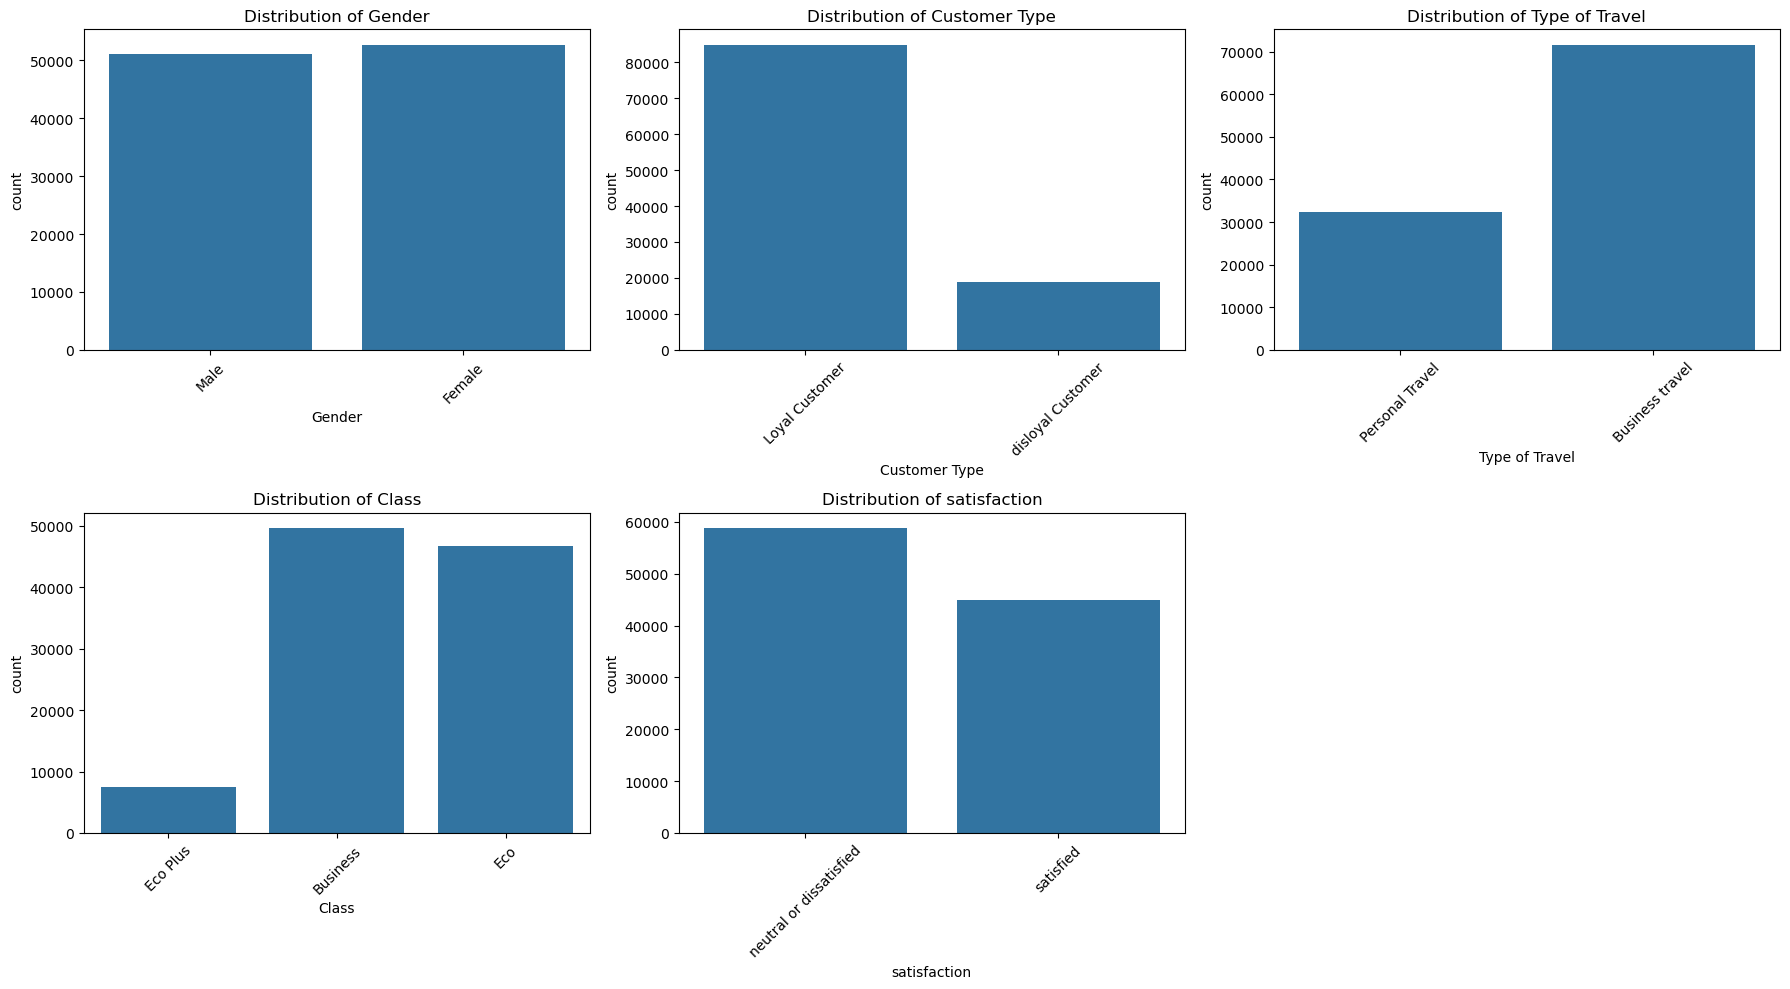

In [57]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for i, col in enumerate(categorical_cols):
    sns.countplot(data=df, x=col, ax=axes.flat[i])
    axes.flat[i].set_title(f'Distribution of {col}')
    axes.flat[i].tick_params(axis='x', rotation=45)

for j in range(len(categorical_cols), 6):
    fig.delaxes(axes.flat[j])

plt.tight_layout()
plt.show()

### Insight
The categorical plots show the distribution of passengers across gender, customer type, type of travel, class, and satisfaction. The distributions indicate that passengers belong to different demographic and travel categories, providing useful information for passenger segmentation.

### Age Distribution

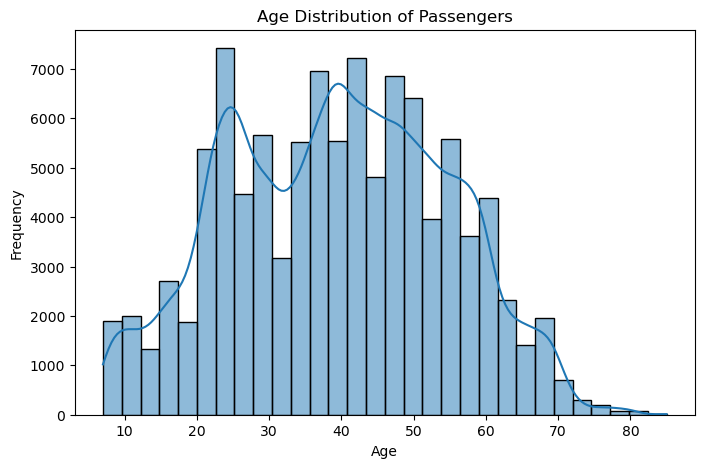

In [58]:
plt.figure(figsize=(8,5))

sns.histplot(df['Age'], bins=30, kde=True)

plt.title('Age Distribution of Passengers')
plt.xlabel('Age')
plt.ylabel('Frequency')

plt.show()

### Insight
The age distribution shows that the dataset contains passengers from different age groups. Most passengers are concentrated within the adult age range, while relatively fewer passengers belong to the very young and older age groups.

### Flight Distance Distribution

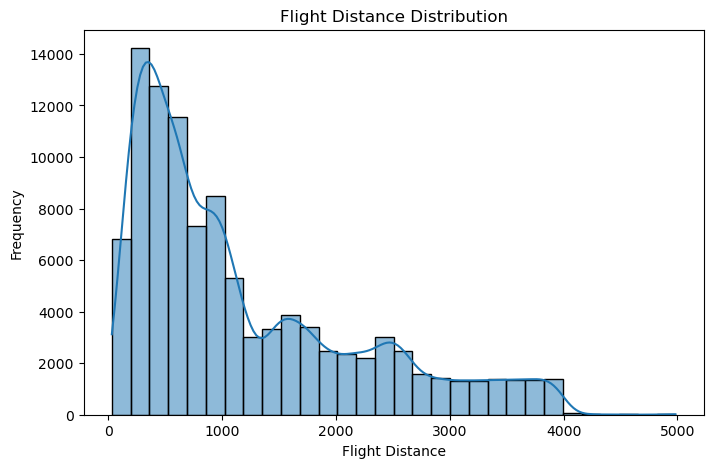

In [59]:
plt.figure(figsize=(8,5))

sns.histplot(df['Flight Distance'], bins=30, kde=True)

plt.title('Flight Distance Distribution')
plt.xlabel('Flight Distance')
plt.ylabel('Frequency')

plt.show()

### Insight
The flight distance distribution shows considerable variation in the distances travelled by passengers. Most passengers travel relatively shorter or medium distances, while a smaller number of passengers travel much longer distances.

### Outlier Analysis

### Age Boxplot

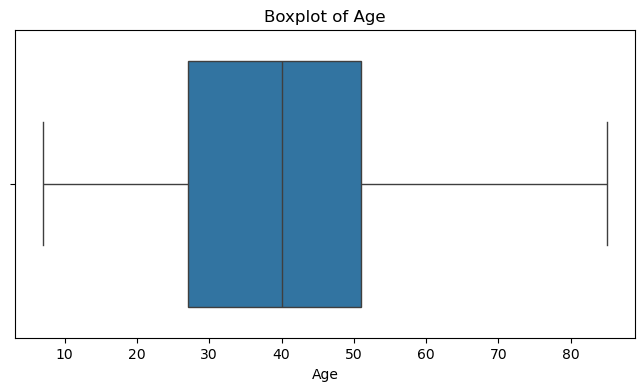

In [60]:
plt.figure(figsize=(8,4))
sns.boxplot(x=df['Age'])
plt.title('Boxplot of Age')

plt.show()

### Insight
The age box plot shows the central distribution and spread of passenger ages. It indicates that age has a moderate range with some variation among passengers.

### Flight Distance Boxplot

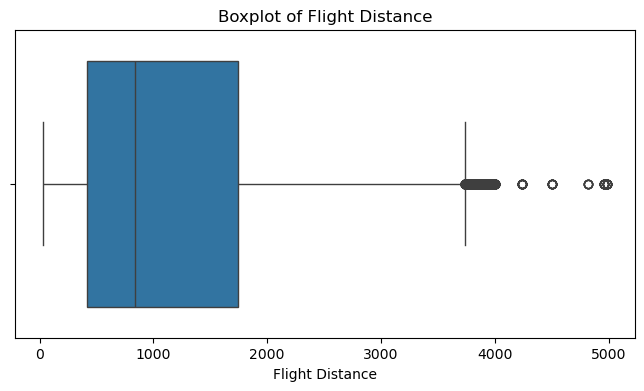

In [61]:
plt.figure(figsize=(8,4))

sns.boxplot(x=df['Flight Distance'])

plt.title('Boxplot of Flight Distance')

plt.show()

### Insight
The Flight Distance box plot shows a wide spread in travel distances and identifies several higher-distance observations as potential outliers.

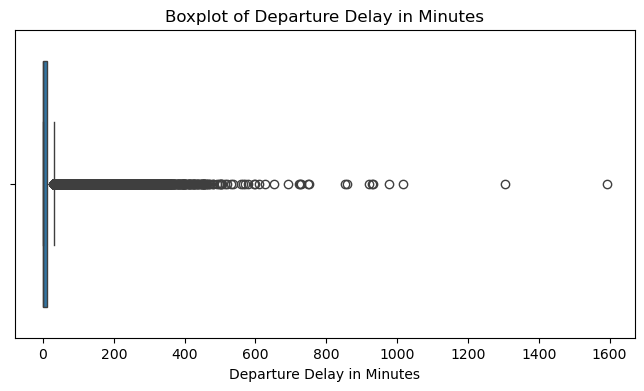

In [62]:
plt.figure(figsize=(8, 4))

sns.boxplot(x=df['Departure Delay in Minutes'])

plt.title('Boxplot of Departure Delay in Minutes')
plt.show()

### Insight
The Departure Delay box plot shows that most passengers experience relatively small delays, while some passengers have considerably higher departure delays, resulting in several potential outliers.

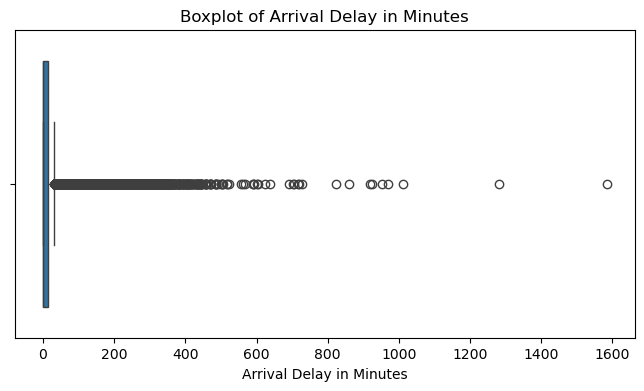

In [63]:
plt.figure(figsize=(8, 4))

sns.boxplot(x=df['Arrival Delay in Minutes'])

plt.title('Boxplot of Arrival Delay in Minutes')
plt.show()

### Insight
The Arrival Delay box plot shows that most arrival delays are relatively low, while a smaller number of passengers experience significantly higher delays.


### Handle Outlier

In [64]:
numerical_check = [
    'Age',
    'Flight Distance',
    'Departure Delay in Minutes',
    'Arrival Delay in Minutes'
]

for col in numerical_check:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    print(f"{col}: {len(outliers)} outliers")

Age: 0 outliers
Flight Distance: 2291 outliers
Departure Delay in Minutes: 14529 outliers
Arrival Delay in Minutes: 13954 outliers


In [65]:
outlier_cols = [
    'Flight Distance',
    'Departure Delay in Minutes',
    'Arrival Delay in Minutes'
]

for col in outlier_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df[col] = df[col].clip(lower_bound, upper_bound)

In [66]:
for col in outlier_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    print(f"{col}: {len(outliers)} outliers")

Flight Distance: 0 outliers
Departure Delay in Minutes: 0 outliers
Arrival Delay in Minutes: 0 outliers


### Correlation Heatmap

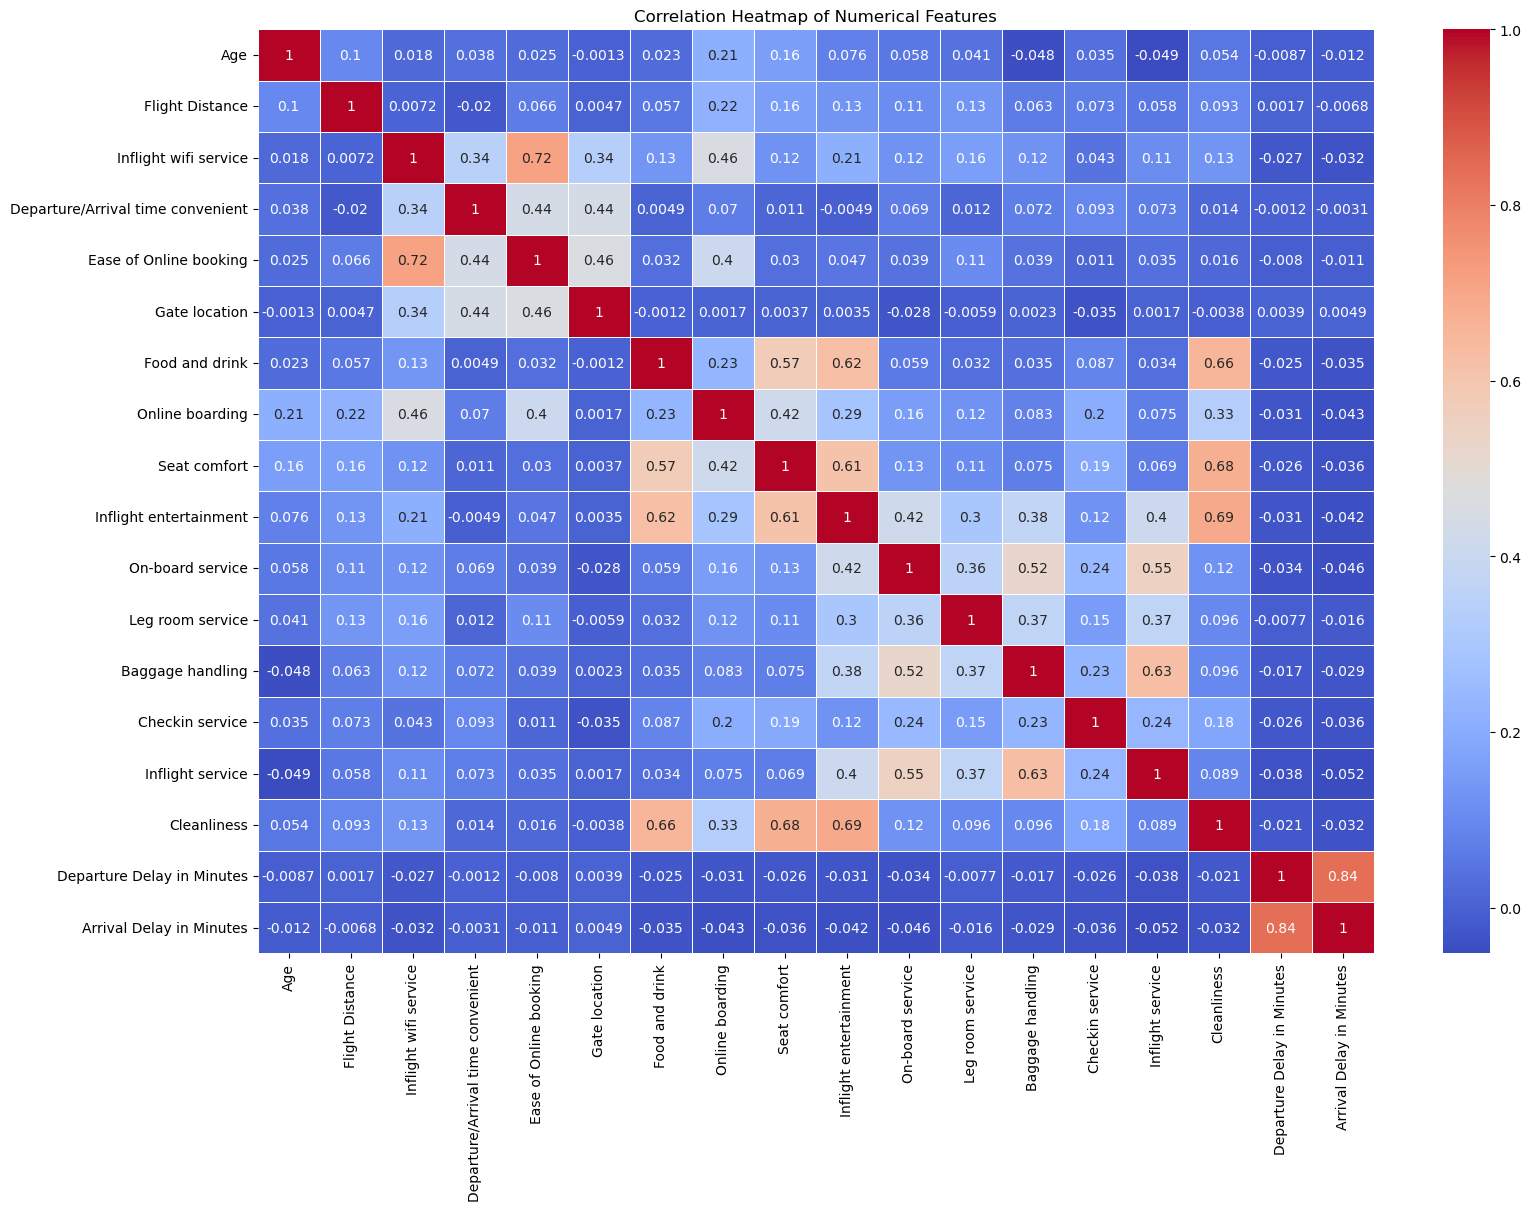

In [67]:
plt.figure(figsize=(18, 12))

corr = df.select_dtypes(include=np.number).corr()

sns.heatmap(
    corr,
    cmap='coolwarm',
    annot=True,
    linewidths=0.5
)

plt.title('Correlation Heatmap of Numerical Features')
plt.show()

### Insight
The correlation analysis shows relationships between different numerical features. Some flight and delay-related features show stronger relationships, while many service-rating features have relatively weaker correlations.

In [68]:
x = df.drop(columns=['satisfaction'])

In [69]:
x.shape

(103904, 22)

### Feature Scaling

In [70]:
numerical_features = x.select_dtypes(include=np.number).columns.tolist()

print(numerical_features)

['Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Inflight service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']


In [71]:
categorical_features = x.select_dtypes(include='object').columns.tolist()

print(categorical_features)

['Gender', 'Customer Type', 'Type of Travel', 'Class']


In [72]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

In [73]:
x_processed = preprocessor.fit_transform(x)

x_processed.shape

(103904, 27)

### K-Mean Clustering

In [74]:
# create sample for cluster evaluation

from sklearn.utils import resample

x_sample = resample(
    x_processed,
    n_samples=10000,
    random_state=42
)

x_sample.shape

(10000, 27)

In [75]:
from sklearn.cluster import KMeans

inertia = []

k_values = list (range(2, 11))

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(x_sample)
    inertia.append(kmeans.inertia_)

### Elbow Method

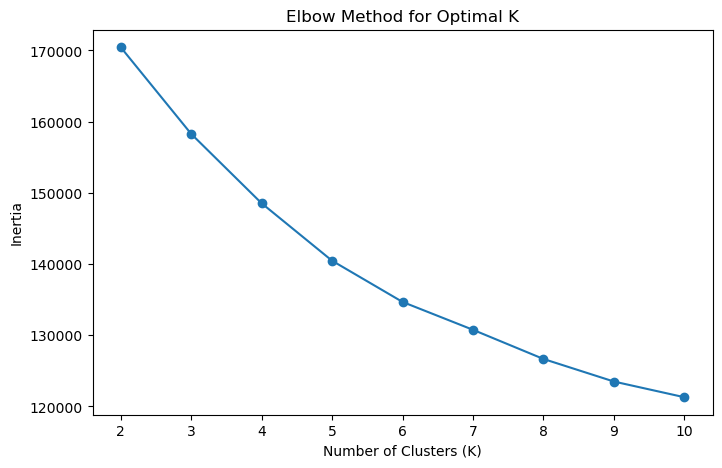

In [76]:
plt.figure(figsize=(8, 5))

plt.plot(k_values, inertia, marker='o')

plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal K')

plt.show()

### Insight
The Elbow Method was used to compare the inertia values for different numbers of clusters. Based on the elbow pattern, K = 4 was selected for K-Means clustering.

In [77]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(x_sample)

print(clusters[:10])

[3 3 2 2 0 0 2 1 2 0]


In [78]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(x_processed)

In [79]:
df['Cluster'] = clusters

In [80]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(x_processed)

df['Cluster'] = clusters

print(df['Cluster'].value_counts().sort_index())

Cluster
0    25430
1    28529
2    25847
3    24098
Name: count, dtype: int64


### PCA Visualization

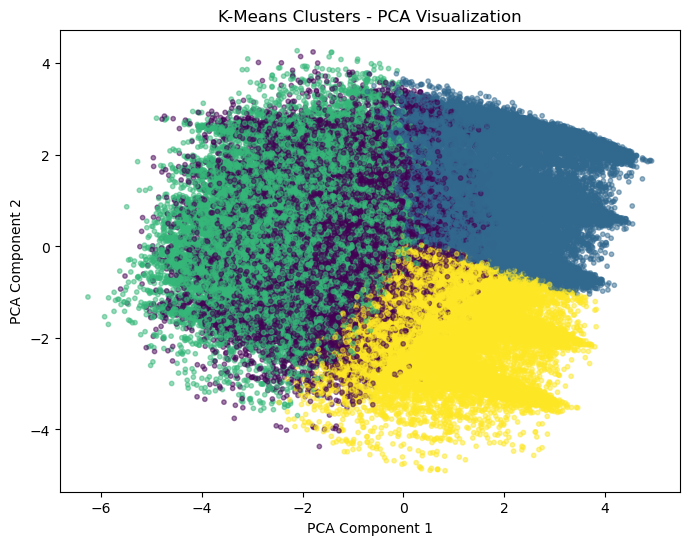

In [81]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2, random_state=42)

X_pca = pca.fit_transform(x_processed)

plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=clusters,
    s=10,
    alpha=0.5
)

plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.title('K-Means Clusters - PCA Visualization')
plt.show()

### Insight
PCA was used to reduce the processed features to two dimensions for visualization. The plot provides a visual representation of the passenger clusters.

### Cluster Evaluation

In [82]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

silhouette = silhouette_score(x_processed, clusters)
davies_bouldin = davies_bouldin_score(x_processed, clusters)

print("Silhouette Score:", silhouette)
print("Davies-Bouldin Index:", davies_bouldin)

Silhouette Score: 0.1036868314062482
Davies-Bouldin Index: 2.4331906010921616


### Insight
Cluster quality was evaluated using Silhouette Score and Davies-Bouldin Index. These metrics help measure the separation and compactness of the generated clusters.

### Hierarchical Clustering

In [83]:
from sklearn.utils import resample

hierarchical_sample = resample(
    x_processed,
    n_samples=2000,
    random_state=42
)

print(hierarchical_sample.shape)

(2000, 27)


In [84]:
from sklearn.cluster import AgglomerativeClustering

hierarchical = AgglomerativeClustering(
    n_clusters=4,
    linkage='ward'
)

hierarchical_clusters = hierarchical.fit_predict(hierarchical_sample)

print(hierarchical_clusters[:10])

[0 0 1 0 0 2 1 2 0 3]


### Insight
Hierarchical Clustering was applied to a sample of passenger data to identify groups using an alternative clustering approach.

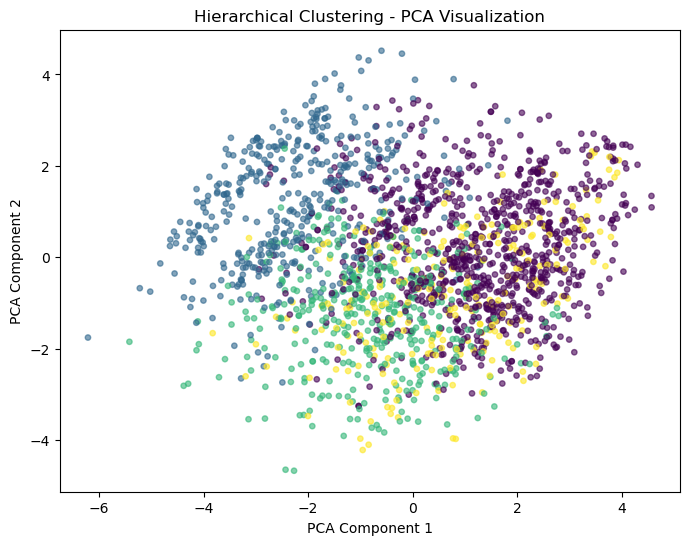

In [85]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca_h = PCA(n_components=2, random_state=42)

hierarchical_pca = pca_h.fit_transform(hierarchical_sample)

plt.figure(figsize=(8, 6))

plt.scatter(
    hierarchical_pca[:, 0],
    hierarchical_pca[:, 1],
    c=hierarchical_clusters,
    s=15,
    alpha=0.6
)

plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.title('Hierarchical Clustering - PCA Visualization')
plt.show()

### Insight
PCA visualization was used to represent the hierarchical clusters in two dimensions and observe the distribution of the generated groups.

### DBSCAN Clustering

In [86]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(
    eps=3,
    min_samples=10
)

dbscan_clusters = dbscan.fit_predict(hierarchical_sample)

print("Number of clusters:", len(set(dbscan_clusters)) - (1 if -1 in dbscan_clusters else 0))
print("Noise points:", list(dbscan_clusters).count(-1))

Number of clusters: 2
Noise points: 798


### Insight
DBSCAN was applied to identify dense passenger groups and detect observations that do not clearly belong to a cluster.

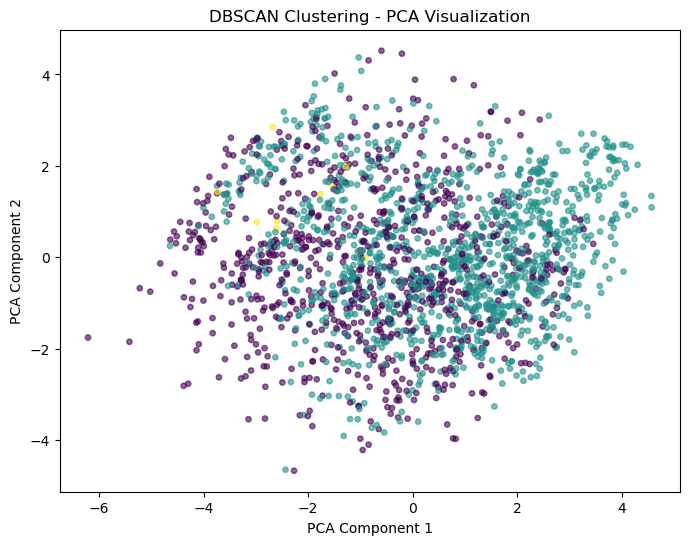

In [87]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca_dbscan = PCA(n_components=2, random_state=42)

dbscan_pca = pca_dbscan.fit_transform(hierarchical_sample)

plt.figure(figsize=(8, 6))

plt.scatter(
    dbscan_pca[:, 0],
    dbscan_pca[:, 1],
    c=dbscan_clusters,
    s=15,
    alpha=0.6
)

plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.title('DBSCAN Clustering - PCA Visualization')
plt.show()

### Insight
PCA visualization was used to display the DBSCAN clusters and noise points in a two-dimensional space.

### Clustering Algorithm Comparison

In [88]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Hierarchical Clustering
hierarchical_silhouette = silhouette_score(
    hierarchical_sample,
    hierarchical_clusters
)

hierarchical_db = davies_bouldin_score(
    hierarchical_sample,
    hierarchical_clusters
)

# DBSCAN
# Check whether DBSCAN produced more than one cluster
dbscan_valid = len(set(dbscan_clusters)) > 1

if dbscan_valid:
    dbscan_silhouette = silhouette_score(
        hierarchical_sample,
        dbscan_clusters
    )
    
    dbscan_db = davies_bouldin_score(
        hierarchical_sample,
        dbscan_clusters
    )
else:
    dbscan_silhouette = None
    dbscan_db = None

print("Hierarchical Silhouette Score:", hierarchical_silhouette)
print("Hierarchical Davies-Bouldin Index:", hierarchical_db)

print("DBSCAN Silhouette Score:", dbscan_silhouette)
print("DBSCAN Davies-Bouldin Index:", dbscan_db)

Hierarchical Silhouette Score: 0.08562813671546818
Hierarchical Davies-Bouldin Index: 2.5479612971467995
DBSCAN Silhouette Score: 0.009888717067657949
DBSCAN Davies-Bouldin Index: 3.7868121766441334


### Insight
K-Means achieved a Silhouette Score of 0.1022 and a Davies-Bouldin Index of 2.4256. Hierarchical Clustering achieved 0.0856 and 2.5480, while DBSCAN achieved 0.0099 and 3.7868 respectively.

### K-Means Evaluation

In [90]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Take the same sample size for K-Means evaluation
kmeans_sample = x_processed[:2000]
kmeans_sample_clusters = clusters[:2000]

kmeans_silhouette = silhouette_score(
    kmeans_sample,
    kmeans_sample_clusters
)

kmeans_db = davies_bouldin_score(
    kmeans_sample,
    kmeans_sample_clusters
)

print("K-Means Silhouette Score:", kmeans_silhouette)
print("K-Means Davies-Bouldin Index:", kmeans_db)

K-Means Silhouette Score: 0.10217830003223642
K-Means Davies-Bouldin Index: 2.4256244677521823


### Cluster-Wise Analysis

In [91]:
cluster_summary = df.groupby('Cluster').mean(numeric_only=True)

cluster_summary

,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes
Cluster,,,,,,,,,,,,,,,,,,
0,43.118600,1088.084762,2.582698,2.894849,2.689697,2.938773,3.421903,3.271215,3.587456,2.860204,2.182344,2.392686,2.386709,2.757059,2.364451,3.372002,8.004837,8.752910
1,41.702653,1444.227698,4.000491,3.973045,3.962109,3.796032,3.720740,4.123208,4.096849,4.240843,4.043500,3.948053,4.196572,3.690631,4.210978,3.918399,6.667952,6.944425
2,32.175804,850.101579,2.325841,3.081209,2.501451,2.979533,1.810616,2.247417,1.905018,1.960692,3.237668,3.253337,3.712849,3.082447,3.729988,1.797733,8.237513,8.998278
3,40.410822,1344.473255,1.813470,2.131878,1.674994,2.044485,3.848743,3.270811,4.150552,4.337538,4.021205,3.760437,4.190306,3.662337,4.215412,4.044361,6.714126,6.994170


### Insight
The four clusters show differences in passenger age, flight distance, and service ratings. Cluster 1 has the highest average flight distance and generally higher service ratings, while Cluster 2 has younger passengers and lower average flight distance.

In [92]:
import joblib

joblib.dump(kmeans, 'airline_kmeans_model.pkl')

print("K-Means model saved successfully!")

K-Means model saved successfully!


### Conclusion
This project successfully performed airline passenger segmentation using unsupervised machine learning techniques. K-Means, Hierarchical Clustering, and DBSCAN were implemented and evaluated using the Elbow Method, Silhouette Score, and Davies-Bouldin Index. Among the evaluated methods, K-Means produced the comparatively better clustering result based on the obtained evaluation metrics. The identified clusters provide useful information about different passenger groups and their characteristics.